# Previsão de evasão no pós-venda Ford

Sprint 3 de IA & Machine Learning · Challenge Ford 2026 · Desafio 2: retenção de clientes no pós-venda

Grupo: Alexia Ramalho (RM 558385), Enzo Real (RM 557943), Gustavo Pasquini (RM 555454), Hellen Silva (RM 559008) e Lorenzo Acquesta (RM 557397).

Objetivo: prever quais clientes vão deixar de fazer serviços na rede Ford nos 12 meses seguintes. A explicação da solução está no `README.md`.

In [1]:
import contextlib
import io
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import seaborn as sns
from mlflow.tracking import MlflowClient
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score, make_scorer,
    precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
AZUL = "#2a78d6"
# cada modelo tem sempre a mesma cor nos gráficos
CORES = {"Regressão Logística": AZUL, "KNN": "#eb6834", "Árvore de Decisão": "#1baf7a", "Random Forest": "#eda100"}
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

## 1. Compreensão do problema

Base sintética de 10 mil clientes, gerada por `gerar_dados.py`.

In [2]:
if not Path("data/clientes_pos_venda.csv").exists():
    import gerar_dados
    gerar_dados.main()

bruto = pd.read_csv("data/clientes_pos_venda.csv")
print(bruto.shape)
bruto.head()

(10100, 22)


,id_cliente,vin,data_referencia,modelo,ano_modelo,km_atual,tipo_uso,regiao,distancia_concessionaria_km,garantia_estendida,plano_manutencao,revisoes_rede_24m,dias_desde_ultima_visita,ticket_medio_rs,nps_ultima_visita,reclamacoes_12m,recall_pendente,sessoes_app_30d,aceita_whatsapp,idade_cliente,motivo_saida_pesquisa,evadiu
0,CLI-09446,9BFSFPMLMEKLLLB33,2025-06-30,Territory,2024,10386.0,particular,Sul,11.1,0,0,1,188,901.60,7.0,0,0,0,1,NaN,NaN,0
1,CLI-00577,9BF5BVA3KSB922X53,2025-06-30,EcoSport,2014,438174.0,Frota,Nordeste,33.2,0,1,4,84,1481.53,10.0,0,0,11,0,64.0,NaN,0
2,CLI-03818,9BFJ0N4S9D29Y31RU,2025-06-30,Territory,2022,21235.0,PF,nordeste,15.6,1,0,6,482,1711.57,9.0,0,0,12,0,32.0,NaN,0
3,CLI-03747,9BF4YLSZ8XSL6XWA7,2025-06-30,Territory,2022,46519.0,particular,Nordeste,6.7,0,0,1,137,1768.83,NaN,1,0,0,1,46.0,NaN,1
4,CLI-06976,9BFGNZTR33U39GDL2,2025-06-30,Ranger,2014,999999.0,frota,Sudeste,9.0,0,0,2,525,2233.51,8.0,0,0,0,0,45.0,NaN,0


### Análise exploratória

In [3]:
proporcao = bruto.drop_duplicates()["evadiu"].map({0: "ficou na rede", 1: "evadiu"}).value_counts()
pd.DataFrame({"clientes": proporcao, "%": (proporcao / proporcao.sum() * 100).round(1)})

,clientes,%
evadiu,,
ficou na rede,7057,70.6
evadiu,2943,29.4


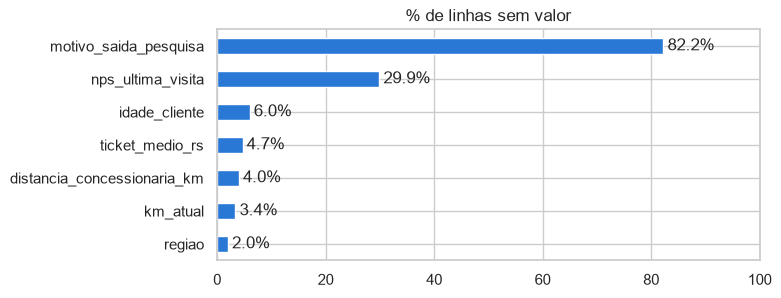

In [4]:
ausentes = bruto.isna().mean().mul(100)
ausentes = ausentes[ausentes > 0].sort_values()
ax = ausentes.plot.barh(color=AZUL, figsize=(7, 3), title="% de linhas sem valor")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_xlim(0, 100)
plt.show()

In [5]:
for coluna in ["modelo", "tipo_uso", "regiao"]:
    print(f"{coluna}: {bruto[coluna].nunique()} grafias diferentes, por exemplo {list(bruto[coluna].dropna().unique()[:8])}")

modelo: 45 grafias diferentes, por exemplo ['Territory', 'EcoSport', 'Ranger', 'Transit', 'Maverick', 'territory', 'Ka', 'F-150']
tipo_uso: 13 grafias diferentes, por exemplo ['particular', 'Frota', 'PF', 'frota', 'aplicativo', 'PARTICULAR', 'pf', 'FROTA']
regiao: 15 grafias diferentes, por exemplo ['Sul', 'Nordeste', 'nordeste', 'Sudeste', 'Centro-Oeste', 'SUDESTE', 'Norte', 'centro-oeste']


In [6]:
bruto.describe().T[["count", "mean", "min", "50%", "max"]].round(1)

,count,mean,min,50%,max
ano_modelo,10100.0,2020.0,2012.0,2021.0,2025.0
km_atual,9760.0,105786.9,-428924.0,59943.0,999999.0
distancia_concessionaria_km,9695.0,23.8,0.5,12.3,2934.4
garantia_estendida,10100.0,0.1,0.0,0.0,1.0
plano_manutencao,10100.0,0.1,0.0,0.0,1.0
revisoes_rede_24m,10100.0,1.7,0.0,1.0,59.0
dias_desde_ultima_visita,10100.0,473.7,-87.0,270.0,2500.0
ticket_medio_rs,9627.0,1357.1,299.2,1109.4,45749.4
nps_ultima_visita,7083.0,7.3,-1.0,7.0,99.0
reclamacoes_12m,10100.0,0.3,0.0,0.0,4.0


Classificação binária supervisionada, com classes desbalanceadas (29,4% de evasão). Métrica principal: PR-AUC.

## 2. Preparação dos dados

### Duplicatas, identificadores e vazamento

In [7]:
print("linhas duplicadas:", bruto.duplicated().sum())
dados = bruto.drop_duplicates().reset_index(drop=True)
print("clientes depois de remover as duplicatas:", len(dados))
pd.crosstab(dados["motivo_saida_pesquisa"].notna().map({True: "tem motivo de saída", False: "sem motivo"}),
            dados["evadiu"].map({0: "ficou", 1: "evadiu"}))

linhas duplicadas: 100
clientes depois de remover as duplicatas: 10000


evadiu,evadiu,ficou
motivo_saida_pesquisa,,
sem motivo,1171,7057
tem motivo de saída,1772,0


`motivo_saida_pesquisa` só existe para quem já evadiu (vazamento), então sai junto com os identificadores.

In [8]:
dados = dados.drop(columns=["id_cliente", "vin", "data_referencia", "motivo_saida_pesquisa"])

### Limpeza: categorias padronizadas e valores impossíveis viram vazio

In [9]:
MODELOS = ["Ranger", "Territory", "Bronco Sport", "Maverick", "F-150", "Mustang Mach-E", "Transit", "Ka", "EcoSport"]
REGIOES = ["Sudeste", "Sul", "Nordeste", "Centro-Oeste", "Norte"]
USOS = {"particular": "particular", "pf": "particular", "aplicativo": "aplicativo",
        "app": "aplicativo", "frota": "frota", "pj": "frota"}

# faixa válida de cada coluna; fora dela o valor vira vazio
LIMITES = {
    "km_atual": (0, 600_000),
    "distancia_concessionaria_km": (0, 800),
    "revisoes_rede_24m": (0, 12),
    "dias_desde_ultima_visita": (0, 5_000),
    "ticket_medio_rs": (0, 10_000),
    "nps_ultima_visita": (0, 10),
    "idade_cliente": (18, 100),
}


def chave(texto):
    # "Bronco-Sport " vira "broncosport"
    return str(texto).lower().replace(" ", "").replace("-", "")


def limpar(df):
    df = df.copy()
    df["modelo"] = df["modelo"].map(chave).map({chave(m): m for m in MODELOS})
    df["tipo_uso"] = df["tipo_uso"].map(chave).map(USOS)
    df["regiao"] = df["regiao"].map(chave).map({chave(r): r for r in REGIOES})
    for coluna, (minimo, maximo) in LIMITES.items():
        df[coluna] = df[coluna].where(df[coluna].between(minimo, maximo))
    return df


limpo = limpar(dados)
colunas = list(LIMITES) + ["modelo", "tipo_uso", "regiao"]
pd.DataFrame({
    "vazios antes": dados[colunas].isna().sum(),
    "vazios depois": limpo[colunas].isna().sum(),
    "valores distintos depois": limpo[colunas].nunique(),
})

,vazios antes,vazios depois,valores distintos depois
km_atual,336,426,9299
distancia_concessionaria_km,402,424,915
revisoes_rede_24m,0,26,9
dias_desde_ultima_visita,0,36,1588
ticket_medio_rs,471,540,9127
nps_ultima_visita,2980,3023,11
idade_cliente,603,626,67
modelo,0,0,9
tipo_uso,0,0,3
regiao,196,196,5


### Outliers: regra do IQR comparada com a nossa regra

In [10]:
def fora_do_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    return (serie < q1 - 1.5 * (q3 - q1)) | (serie > q3 + 1.5 * (q3 - q1))


colunas = ["km_atual", "distancia_concessionaria_km", "ticket_medio_rs", "revisoes_rede_24m", "idade_cliente"]
pd.DataFrame({
    "fora do IQR": [fora_do_iqr(dados[c]).sum() for c in colunas],
    "impossíveis (nossa regra)": [(limpo[c].isna() & dados[c].notna()).sum() for c in colunas],
}, index=colunas)

,fora do IQR,impossíveis (nossa regra)
km_atual,898,90
distancia_concessionaria_km,727,22
ticket_medio_rs,365,69
revisoes_rede_24m,256,26
idade_cliente,46,23


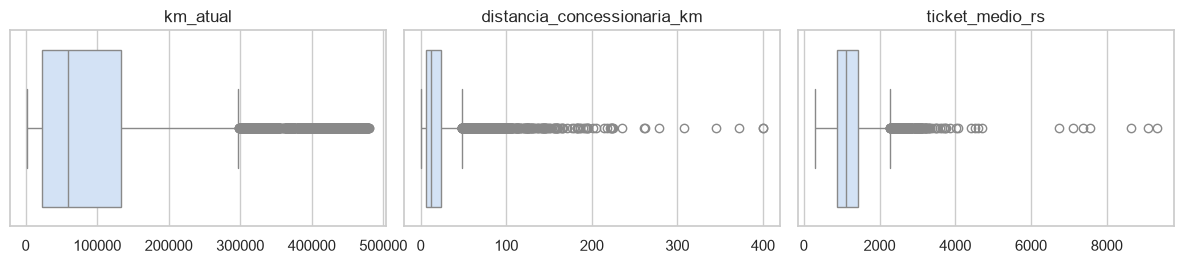

In [11]:
fig, eixos = plt.subplots(1, 3, figsize=(12, 2.8))
for ax, coluna in zip(eixos, ["km_atual", "distancia_concessionaria_km", "ticket_medio_rs"]):
    sns.boxplot(x=limpo[coluna], ax=ax, color="#cde2fb")
    ax.set(title=coluna, xlabel="")
plt.tight_layout()
plt.show()

### Novas variáveis

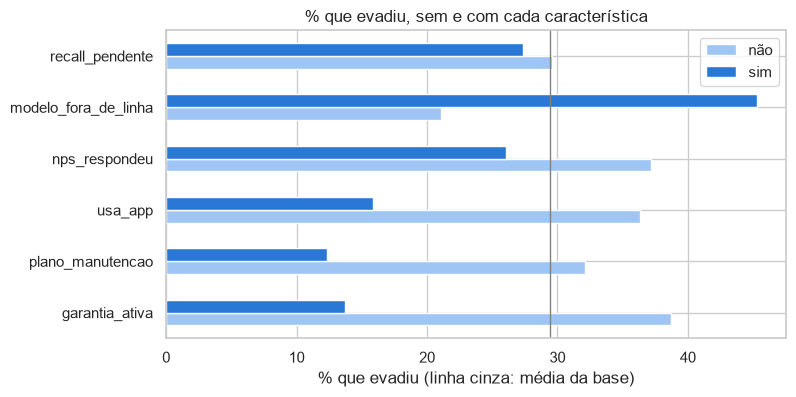

In [12]:
def criar_variaveis(df):
    df = df.copy()
    df["idade_veiculo_anos"] = (2025 - df["ano_modelo"]).clip(lower=0)
    # carro com menos de 1 ano conta como meio ano, senão o km por ano explode
    df["km_por_ano"] = df["km_atual"] / df["idade_veiculo_anos"].clip(lower=0.5)
    # premissa nossa: garantia de fábrica de 3 anos, ou 5 com a estendida
    df["garantia_ativa"] = ((df["idade_veiculo_anos"] < 3)
                            | ((df["garantia_estendida"] == 1) & (df["idade_veiculo_anos"] < 5))).astype(int)
    df["nps_respondeu"] = df["nps_ultima_visita"].notna().astype(int)
    df["modelo_fora_de_linha"] = df["modelo"].isin(["Ka", "EcoSport"]).astype(int)
    df["usa_app"] = (df["sessoes_app_30d"] > 0).astype(int)
    return df


dados = criar_variaveis(limpo)

binarias = ["garantia_ativa", "plano_manutencao", "usa_app", "nps_respondeu", "modelo_fora_de_linha", "recall_pendente"]
taxas = pd.DataFrame({c: dados.groupby(c)["evadiu"].mean() * 100 for c in binarias}).T
taxas.columns = ["não", "sim"]
ax = taxas.plot.barh(figsize=(8, 4), color=["#9ec5f4", AZUL], title="% que evadiu, sem e com cada característica")
ax.axvline(dados["evadiu"].mean() * 100, color="gray", linewidth=1)
ax.set_xlabel("% que evadiu (linha cinza: média da base)")
plt.show()

In [13]:
faixas = pd.cut(dados["dias_desde_ultima_visita"], [0, 90, 180, 365, 730, 5000],
                labels=["até 90", "91 a 180", "181 a 365", "366 a 730", "mais de 730"])
dados.groupby(faixas, observed=True)["evadiu"].mean().mul(100).round(1).to_frame("% que evadiu")

,% que evadiu
dias_desde_ultima_visita,
até 90,12.0
91 a 180,11.9
181 a 365,13.7
366 a 730,35.7
mais de 730,62.4


### Treino e teste (80/20, estratificado)

In [14]:
X = dados.drop(columns="evadiu")
y = dados["evadiu"]
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
pd.DataFrame({"clientes": [len(y_treino), len(y_teste)], "% que evadiu": [y_treino.mean() * 100, y_teste.mean() * 100]},
             index=["treino", "teste"]).round(1)

,clientes,% que evadiu
treino,8000,29.4
teste,2000,29.4


### Seleção de variáveis (só no treino)

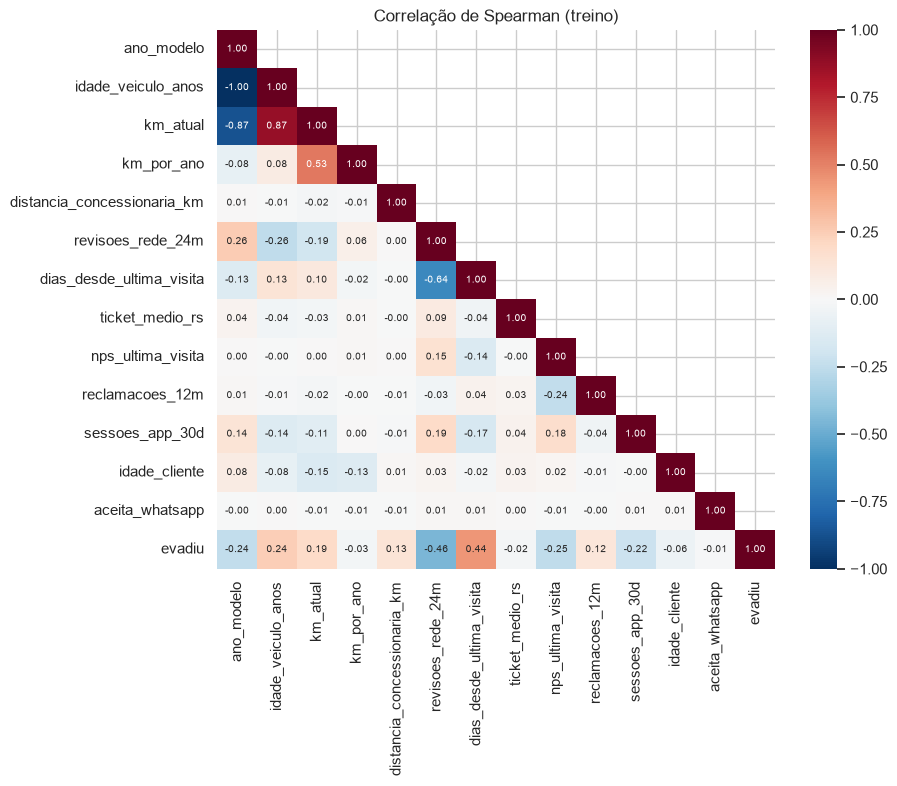

In [15]:
numericas = ["ano_modelo", "idade_veiculo_anos", "km_atual", "km_por_ano", "distancia_concessionaria_km",
             "revisoes_rede_24m", "dias_desde_ultima_visita", "ticket_medio_rs", "nps_ultima_visita",
             "reclamacoes_12m", "sessoes_app_30d", "idade_cliente", "aceita_whatsapp"]
correlacao = X_treino[numericas].assign(evadiu=y_treino).corr(method="spearman")
plt.figure(figsize=(9, 7))
sns.heatmap(correlacao, mask=np.triu(np.ones_like(correlacao, dtype=bool), k=1), cmap="RdBu_r",
            vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"fontsize": 7})
plt.title("Correlação de Spearman (treino)")
plt.show()

Saem `ano_modelo` e `km_atual`, que repetem a idade do carro, e `idade_cliente` e `aceita_whatsapp`, sem relação com a evasão.

In [16]:
NUM_LOG = ["distancia_concessionaria_km", "ticket_medio_rs", "km_por_ano", "sessoes_app_30d"]
NUM = ["idade_veiculo_anos", "revisoes_rede_24m", "dias_desde_ultima_visita", "nps_ultima_visita", "reclamacoes_12m"]
CAT = ["modelo", "tipo_uso", "regiao"]
BIN = ["garantia_estendida", "plano_manutencao", "recall_pendente", "garantia_ativa", "nps_respondeu",
       "modelo_fora_de_linha", "usa_app"]
print(len(NUM_LOG + NUM + CAT + BIN), "variáveis entram no modelo")

19 variáveis entram no modelo


### Transformação: imputação, log, padronização e one-hot

In [17]:
pd.DataFrame({"assimetria antes": X_treino[NUM_LOG].skew(), "depois do log": np.log1p(X_treino[NUM_LOG]).skew()}).round(2)

,assimetria antes,depois do log
distancia_concessionaria_km,4.69,0.31
ticket_medio_rs,3.27,0.27
km_por_ano,1.75,0.50
sessoes_app_30d,1.44,0.85


In [18]:
preprocessamento = ColumnTransformer([
    ("num_log", Pipeline([("imputar", SimpleImputer(strategy="median")),
                          ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                          ("padronizar", StandardScaler())]), NUM_LOG),
    ("num", Pipeline([("imputar", SimpleImputer(strategy="median")), ("padronizar", StandardScaler())]), NUM),
    ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CAT),
    ("bin", SimpleImputer(strategy="most_frequent"), BIN),
], verbose_feature_names_out=False)


def com_preprocessamento(modelo):
    return Pipeline([("prep", clone(preprocessamento)), ("modelo", modelo)])


print("colunas depois do pré-processamento:", preprocessamento.fit_transform(X_treino).shape[1])

colunas depois do pré-processamento: 33


## 3. Desenvolvimento dos modelos

Validação cruzada estratificada com 5 folds no treino.

In [19]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
METRICAS = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "f1": make_scorer(f1_score, zero_division=0),
    "recall": "recall",
    "precisao": make_scorer(precision_score, zero_division=0),
    "acuracia": "accuracy",
}

### Linha de base

In [20]:
linhas = {}
for estrategia, nome in [("most_frequent", "sempre 'ficou'"), ("stratified", "sorteio")]:
    r = cross_validate(com_preprocessamento(DummyClassifier(strategy=estrategia, random_state=SEED)),
                       X_treino, y_treino, cv=CV, scoring=METRICAS)
    linhas[f"Dummy ({nome})"] = {m: r[f"test_{m}"].mean() for m in METRICAS}
pd.DataFrame(linhas).T.round(3)

,pr_auc,roc_auc,f1,recall,precisao,acuracia
Dummy (sempre 'ficou'),0.294,0.500,0.000,0.000,0.000,0.706
Dummy (sorteio),0.296,0.503,0.297,0.296,0.299,0.588


### Parâmetros padrão

In [21]:
MODELOS_PADRAO = {
    "Regressão Logística": LogisticRegression(max_iter=2000),
    "KNN": KNeighborsClassifier(),
    "Árvore de Decisão": DecisionTreeClassifier(random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
}
linhas = {}
for nome, modelo in MODELOS_PADRAO.items():
    r = cross_validate(com_preprocessamento(modelo), X_treino, y_treino, cv=CV, scoring=METRICAS,
                       return_train_score=True, n_jobs=-1)
    linhas[nome] = {"PR-AUC (CV)": r["test_pr_auc"].mean(), "desvio": r["test_pr_auc"].std(),
                    "ROC-AUC (CV)": r["test_roc_auc"].mean(), "F1 (CV)": r["test_f1"].mean(),
                    "PR-AUC (treino)": r["train_pr_auc"].mean()}
pd.DataFrame(linhas).T.round(3)

,PR-AUC (CV),desvio,ROC-AUC (CV),F1 (CV),PR-AUC (treino)
Regressão Logística,0.733,0.013,0.870,0.653,0.739
KNN,0.598,0.009,0.804,0.597,0.777
Árvore de Decisão,0.422,0.009,0.670,0.535,1.000
Random Forest,0.710,0.016,0.861,0.646,1.000


### Ajuste de hiperparâmetros (80 configurações)

In [22]:
GRADES = {
    "Regressão Logística": (
        LogisticRegression(solver="liblinear", max_iter=2000, random_state=SEED),
        {"modelo__C": [0.01, 0.1, 1, 10], "modelo__l1_ratio": [0.0, 1.0], "modelo__class_weight": [None, "balanced"]},
    ),
    "KNN": (
        KNeighborsClassifier(),
        {"modelo__n_neighbors": [5, 15, 31, 61], "modelo__weights": ["uniform", "distance"], "modelo__p": [1, 2]},
    ),
    "Árvore de Decisão": (
        DecisionTreeClassifier(random_state=SEED),
        {"modelo__max_depth": [3, 5, 8, None], "modelo__min_samples_leaf": [1, 25, 100],
         "modelo__class_weight": [None, "balanced"]},
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
        {"modelo__max_depth": [8, 16, None], "modelo__min_samples_leaf": [1, 5], "modelo__max_features": ["sqrt", 0.5],
         "modelo__class_weight": [None, "balanced_subsample"]},
    ),
}

buscas = {}
for nome, (modelo, grade) in GRADES.items():
    buscas[nome] = GridSearchCV(com_preprocessamento(modelo), grade, scoring=METRICAS, refit="pr_auc", cv=CV,
                                n_jobs=-1, return_train_score=True).fit(X_treino, y_treino)

resumo = pd.DataFrame({
    nome: {
        "melhor configuração": {k.replace("modelo__", ""): v for k, v in b.best_params_.items()},
        "PR-AUC (CV)": round(b.best_score_, 4),
        "desvio": round(b.cv_results_["std_test_pr_auc"][b.best_index_], 4),
        "ROC-AUC (CV)": round(b.cv_results_["mean_test_roc_auc"][b.best_index_], 4),
    }
    for nome, b in buscas.items()
}).T.sort_values("PR-AUC (CV)", ascending=False)
resumo

,melhor configuração,PR-AUC (CV),desvio,ROC-AUC (CV)
Regressão Logística,"{'C': 0.1, 'class_weight': None, 'l1_ratio': 1.0}",0.734,0.0134,0.8702
Random Forest,"{'class_weight': None, 'max_depth': 16, 'max_f...",0.7211,0.0165,0.8653
KNN,"{'n_neighbors': 61, 'p': 2, 'weights': 'distan...",0.7129,0.0235,0.8578
Árvore de Decisão,"{'class_weight': None, 'max_depth': 8, 'min_sa...",0.669,0.0191,0.8374


Configurações testadas na Regressão Logística:

In [23]:
tabela_lr = pd.DataFrame(buscas["Regressão Logística"].cv_results_)[
    ["param_modelo__C", "param_modelo__l1_ratio", "param_modelo__class_weight",
     "mean_test_pr_auc", "mean_test_recall", "mean_train_pr_auc"]]
tabela_lr.columns = ["C", "l1_ratio (1 = L1)", "class_weight", "PR-AUC (CV)", "recall (CV)", "PR-AUC (treino)"]
tabela_lr.sort_values("PR-AUC (CV)", ascending=False).round(4)

,C,l1_ratio (1 = L1),class_weight,PR-AUC (CV),recall (CV),PR-AUC (treino)
5,0.10,1.0,None,0.7340,0.5981,0.7374
4,0.10,0.0,None,0.7339,0.5986,0.7385
9,1.00,1.0,None,0.7336,0.5998,0.7386
7,0.10,1.0,balanced,0.7335,0.7999,0.7367
8,1.00,0.0,None,0.7335,0.6007,0.7386
13,10.00,1.0,None,0.7335,0.6015,0.7386
6,0.10,0.0,balanced,0.7335,0.8037,0.7375
12,10.00,0.0,None,0.7333,0.6011,0.7386
11,1.00,1.0,balanced,0.7332,0.8020,0.7376
10,1.00,0.0,balanced,0.7331,0.8042,0.7375


### Escolha do modelo e do limiar

Vence a maior PR-AUC no CV; se a diferença for menor que um desvio padrão, fica o modelo mais simples. O limiar sai das previsões out-of-fold do treino (maior F1).

In [24]:
ORDEM_SIMPLICIDADE = ["Regressão Logística", "Árvore de Decisão", "Random Forest", "KNN"]
lider = resumo.index[0]
empatados = [n for n in resumo.index
             if resumo.loc[lider, "PR-AUC (CV)"] - resumo.loc[n, "PR-AUC (CV)"] < resumo.loc[lider, "desvio"]]
campeao = min(empatados, key=ORDEM_SIMPLICIDADE.index)
modelo_final = buscas[campeao].best_estimator_
print("líder:", lider, "| empatados:", empatados, "| escolhido:", campeao)

líder: Regressão Logística | empatados: ['Regressão Logística', 'Random Forest'] | escolhido: Regressão Logística


In [25]:
proba_oof = cross_val_predict(modelo_final, X_treino, y_treino, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
precisoes, recalls, limiares = precision_recall_curve(y_treino, proba_oof)
f1s = 2 * precisoes[:-1] * recalls[:-1] / (precisoes[:-1] + recalls[:-1] + 1e-12)
limiar = limiares[np.argmax(f1s)]
corte_alta, corte_media = np.quantile(proba_oof, [0.8, 0.5])
print(f"limiar que maximiza o F1: {limiar:.3f}")
print(f"prioridade alta a partir de {corte_alta:.3f}, média a partir de {corte_media:.3f}")

limiar que maximiza o F1: 0.322
prioridade alta a partir de 0.577, média a partir de 0.194


## 4. Avaliação no teste

In [26]:
def metricas(y_real, proba, limiar_decisao=0.5):
    previsto = (proba >= limiar_decisao).astype(int)
    return {
        "PR-AUC": average_precision_score(y_real, proba),
        "ROC-AUC": roc_auc_score(y_real, proba),
        "F1": f1_score(y_real, previsto, zero_division=0),
        "recall": recall_score(y_real, previsto, zero_division=0),
        "precisão": precision_score(y_real, previsto, zero_division=0),
        "acurácia": accuracy_score(y_real, previsto),
    }


linhas = {"Dummy (sempre 'ficou')": metricas(y_teste, np.zeros(len(y_teste)))}
for nome, modelo in MODELOS_PADRAO.items():
    proba = com_preprocessamento(clone(modelo)).fit(X_treino, y_treino).predict_proba(X_teste)[:, 1]
    linhas[f"{nome} (padrão)"] = metricas(y_teste, proba)
probas = {nome: b.predict_proba(X_teste)[:, 1] for nome, b in buscas.items()}
for nome, proba in probas.items():
    linhas[f"{nome} (ajustado)"] = metricas(y_teste, proba)
linhas[f"{campeao} (ajustado, limiar {limiar:.2f})"] = metricas(y_teste, probas[campeao], limiar)
tabela_teste = pd.DataFrame(linhas).T
tabela_teste.round(3)

,PR-AUC,ROC-AUC,F1,recall,precisão,acurácia
Dummy (sempre 'ficou'),0.294,0.500,0.000,0.000,0.000,0.706
Regressão Logística (padrão),0.753,0.872,0.658,0.593,0.741,0.819
KNN (padrão),0.592,0.793,0.587,0.540,0.642,0.776
Árvore de Decisão (padrão),0.428,0.674,0.540,0.537,0.543,0.730
Random Forest (padrão),0.715,0.856,0.636,0.564,0.730,0.810
Regressão Logística (ajustado),0.751,0.872,0.650,0.584,0.732,0.814
KNN (ajustado),0.727,0.857,0.619,0.533,0.739,0.807
Árvore de Decisão (ajustado),0.686,0.841,0.635,0.596,0.679,0.798
Random Forest (ajustado),0.726,0.861,0.637,0.565,0.730,0.810
"Regressão Logística (ajustado, limiar 0.32)",0.751,0.872,0.683,0.761,0.620,0.792


### Curvas ROC e precisão-recall

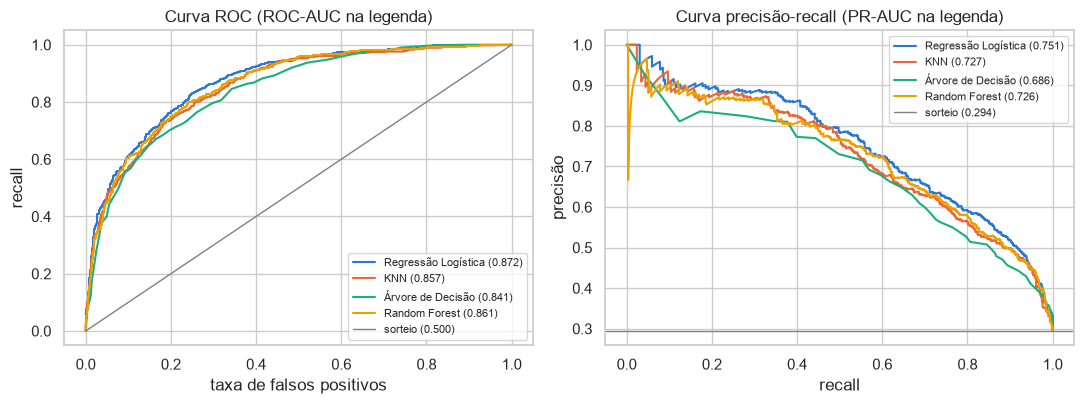

In [27]:
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 4.2))
for nome, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_teste, proba)
    ax_roc.plot(fpr, tpr, color=CORES[nome], label=f"{nome} ({roc_auc_score(y_teste, proba):.3f})")
    precisao_c, recall_c, _ = precision_recall_curve(y_teste, proba)
    ax_pr.plot(recall_c, precisao_c, color=CORES[nome], label=f"{nome} ({average_precision_score(y_teste, proba):.3f})")
ax_roc.plot([0, 1], [0, 1], color="gray", linewidth=1, label="sorteio (0.500)")
ax_pr.axhline(y_teste.mean(), color="gray", linewidth=1, label=f"sorteio ({y_teste.mean():.3f})")
ax_roc.set(title="Curva ROC (ROC-AUC na legenda)", xlabel="taxa de falsos positivos", ylabel="recall")
ax_pr.set(title="Curva precisão-recall (PR-AUC na legenda)", xlabel="recall", ylabel="precisão")
ax_roc.legend(fontsize=8)
ax_pr.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Matriz de confusão do modelo escolhido

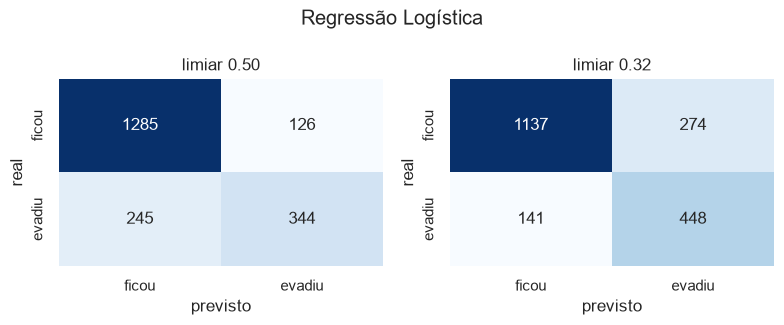

In [28]:
fig, eixos = plt.subplots(1, 2, figsize=(8, 3.3))
for ax, corte in zip(eixos, [0.5, limiar]):
    matriz = confusion_matrix(y_teste, (probas[campeao] >= corte).astype(int))
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["ficou", "evadiu"], yticklabels=["ficou", "evadiu"])
    ax.set(title=f"limiar {corte:.2f}", xlabel="previsto", ylabel="real")
fig.suptitle(campeao)
plt.tight_layout()
plt.show()

### Curva de ganho

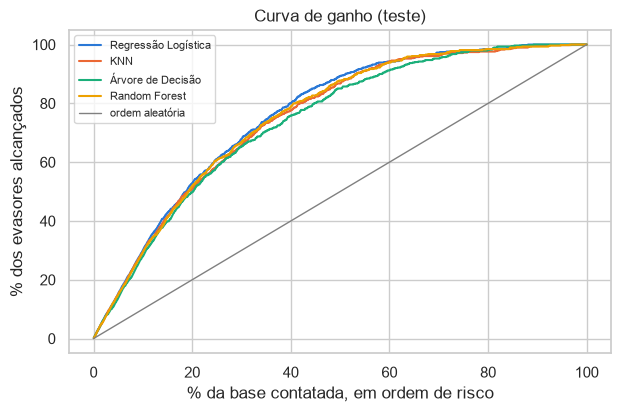

,top 10%,top 20%,top 30%,top 50%
Regressão Logística,30.1,52.8,67.7,89.3
KNN,29.4,50.9,65.9,86.8
Árvore de Decisão,28.0,49.7,65.4,85.1
Random Forest,29.4,52.0,66.9,87.8


In [29]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ganhos = {}
for nome, proba in probas.items():
    ordem = np.argsort(-proba)
    capturados = np.cumsum(y_teste.values[ordem]) / y_teste.sum() * 100
    contatados = np.arange(1, len(proba) + 1) / len(proba) * 100
    ax.plot(contatados, capturados, color=CORES[nome], label=nome)
    ganhos[nome] = {f"top {p}%": capturados[int(len(proba) * p / 100) - 1] for p in (10, 20, 30, 50)}
ax.plot([0, 100], [0, 100], color="gray", linewidth=1, label="ordem aleatória")
ax.set(title="Curva de ganho (teste)", xlabel="% da base contatada, em ordem de risco", ylabel="% dos evasores alcançados")
ax.legend(fontsize=8)
plt.show()
pd.DataFrame(ganhos).T.round(1)

### Sobreajuste

In [30]:
pd.DataFrame({
    nome: {
        "PR-AUC treino": average_precision_score(y_treino, b.predict_proba(X_treino)[:, 1]),
        "PR-AUC CV": b.best_score_,
        "desvio CV": b.cv_results_["std_test_pr_auc"][b.best_index_],
        "PR-AUC teste": average_precision_score(y_teste, probas[nome]),
    }
    for nome, b in buscas.items()
}).T.round(3)

,PR-AUC treino,PR-AUC CV,desvio CV,PR-AUC teste
Regressão Logística,0.737,0.734,0.013,0.751
KNN,1.000,0.713,0.023,0.727
Árvore de Decisão,0.707,0.669,0.019,0.686
Random Forest,0.897,0.721,0.016,0.726


### Registro no MLflow

Para abrir: `mlflow ui --backend-store-uri sqlite:///mlflow.db`

In [31]:
logging.getLogger("mlflow").setLevel(logging.ERROR)
mlflow.set_tracking_uri("sqlite:///mlflow.db")
# na primeira execução o MLflow cria as tabelas do banco e despeja dezenas de linhas de log
with contextlib.redirect_stderr(io.StringIO()):
    mlflow.set_experiment("ford-churn-pos-venda")

for nome, busca in buscas.items():
    resultados = busca.cv_results_
    for i, parametros in enumerate(resultados["params"]):
        with mlflow.start_run(run_name=f"{nome} #{i + 1:02d}"):
            mlflow.set_tag("algoritmo", nome)
            mlflow.log_params({k.replace("modelo__", ""): str(v) for k, v in parametros.items()})
            mlflow.log_metrics({f"cv_{m}": resultados[f"mean_test_{m}"][i] for m in METRICAS})

with mlflow.start_run(run_name=f"modelo final ({campeao})"):
    mlflow.log_params({k.replace("modelo__", ""): str(v) for k, v in buscas[campeao].best_params_.items()})
    mlflow.log_param("limiar", round(float(limiar), 4))
    mlflow.log_metrics({f"teste_{m}": v for m, v in zip(METRICAS, metricas(y_teste, probas[campeao], limiar).values())})
    info = mlflow.sklearn.log_model(modelo_final, artifact_path="model")

versao = mlflow.register_model(info.model_uri, "ford-churn-pos-venda")
MlflowClient().set_registered_model_alias("ford-churn-pos-venda", "champion", versao.version)
print(f"modelo ford-churn-pos-venda v{versao.version} registrado com o alias @champion")

Successfully registered model 'ford-churn-pos-venda'.
Created version '1' of model 'ford-churn-pos-venda'.


modelo ford-churn-pos-venda v1 registrado com o alias @champion


## 5. Coeficientes do modelo escolhido

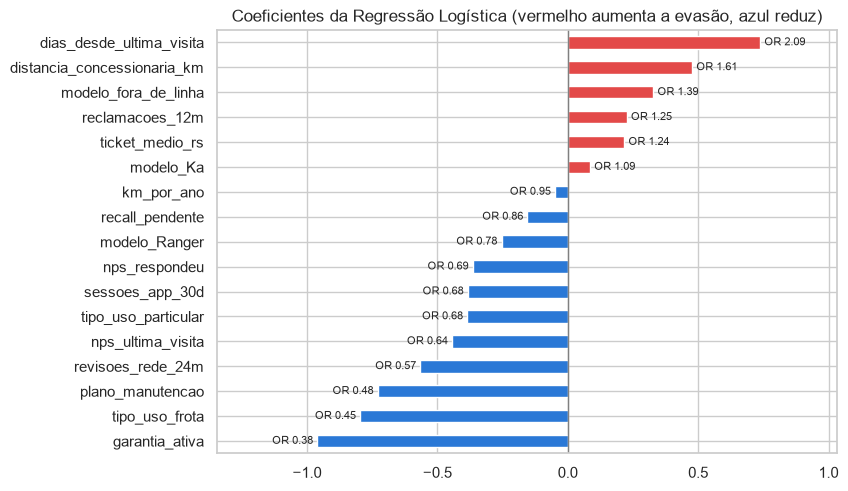

coeficientes zerados pela penalidade L1: 16 de 33


In [32]:
regressao = buscas["Regressão Logística"].best_estimator_
coeficientes = pd.Series(regressao.named_steps["modelo"].coef_[0],
                         index=regressao.named_steps["prep"].get_feature_names_out())
ativos = coeficientes[coeficientes != 0].sort_values()
ax = ativos.plot.barh(figsize=(8, 5.5), color=["#e34948" if v > 0 else AZUL for v in ativos],
                      title="Coeficientes da Regressão Logística (vermelho aumenta a evasão, azul reduz)")
ax.bar_label(ax.containers[0], labels=[f"OR {np.exp(v):.2f}" for v in ativos], padding=3, fontsize=8)
ax.set_xlim(ativos.min() * 1.4, ativos.max() * 1.4)
ax.axvline(0, color="gray", linewidth=1)
plt.show()
print(f"coeficientes zerados pela penalidade L1: {(coeficientes == 0).sum()} de {len(coeficientes)}")

## 6. Conclusão

- Modelo escolhido: Regressão Logística com penalidade L1 (C = 0,1) e limiar 0,32. Empatou com a Random Forest no CV e é mais simples de explicar.
- No teste: PR-AUC de 0,751, ROC-AUC de 0,872, recall de 76% e precisão de 62%.
- Ligando para os 20% de maior risco, a concessionária alcança 53% dos evasores.

Taxa real de evasão por prioridade de contato no teste:

In [33]:
prioridade = np.select([probas[campeao] >= corte_alta, probas[campeao] >= corte_media], ["alta", "média"], "baixa")
(pd.Series(y_teste.values).groupby(prioridade).agg(["size", "mean"]).reindex(["alta", "média", "baixa"])
 .rename(columns={"size": "clientes", "mean": "taxa real de evasão"}).round(3))

,clientes,taxa real de evasão
alta,372,0.788
média,624,0.372
baixa,1004,0.064


Uso no CarSync, deploy, limitações e próximos passos estão no `README.md`.